# Example Notebook for RCM emulator

In [3]:
from datetime import datetime
from pathlib import Path

import xarray as xr
from download_data import download_data

from super_resolution import rcm_emulator_entrypoint

%load_ext autoreload
%autoreload 2

[    INFO 2026-07-30 CEST 14:11:25.114 pid 49063,                        main.py, ln  33, in                  <module>()] Available datasets: CLIMATE_DT_SCENARIO_MIP_IFS_NEMO, CLIMATE_DT_SCENARIO_MIP_ICON, ERA5_REANALYSIS_HOURLY, ERA5_REANALYSIS_MONTHLY_MEANS, 4D_ANTARCTICA_SUBGLACIAL_LAKES, 4D_ANTARCTICA_SURFACE_MELT_MAPS, ANTARCTIC_OSCILLATION, BAS_OCEAN_MOORINGS, BED_MACHINE, C3S_SEA_ICE_CONCENTRATION, C3S_SEA_ICE_EDGE, GLORYS12V1, ICE_LINES_FRONTS_QUARTERLY, ICE_LINES_FRONTS_ANNUAL, ICE_LINES_FRONTS_MONTHLY, ICE_LINES_FRONTS_DAILY, ICE_LINES_FRONTS_ELIM_DAILY, ICE_LINES_FRONTS_ELIM_MONTHLY, ICE_LINES_FRONTS_ELIM_QUARTERLY, ICE_LINES_FRONTS_ELIM_ANNUAL, ITS_LIVE_ICE_VELOCITY, ITS_LIVE_BASAL_MELT, ICE_VELOCITY-S1-MONTHLY, ICE_VELOCITY-S1-YEARLY, POLAR_PLUS_ICE_SHELVES_BASAL_MELT, POLAR_PLUS_ICE_SHELVES_BASAL_MELT_TIMESERIES, POLAR_PLUS_ICE_SHELVES_CALVING_FRONT, POLAR_PLUS_ICE_SHELVES_MASS_BALANCE_COMPONENTS, RACMO, REMA_MOSAIC_1000, REMA_MOSAIC_100, REMA_GAPLESS_100, SOUTHERN_ANNULA

Download the data from the DDM (Data Download Module):

In [ ]:
START_DATE = datetime(2023, 1, 1)
END_DATE = datetime(2023, 5, 1)
OUTPUT_DIR = Path.cwd() / "local_data"

In [ ]:
data_paths = download_data(START_DATE, END_DATE, OUTPUT_DIR)

gcm_path = data_paths["era5"]
rcm_path = data_paths["racmo"]

Call the emulator entrypoint

In [ ]:
a = START_DATE.strftime("%Y-%m-%d")[:-3]
b = END_DATE.strftime("%Y-%m-%d")[:-3]
OUTPUT_PATH = OUTPUT_DIR / f"preds_{'_'.join([a, b])}.zarr"

In [ ]:
rcm_emulator_entrypoint.main(
    gcm_path=gcm_path,
    rcm_path=rcm_path,
    output_zarr_path=OUTPUT_PATH,
    model_name="model_attention_unet")

Read and plot the output

In [ ]:
preds_ds = xr.open_zarr(OUTPUT_PATH)

Number of time steps (months): 5


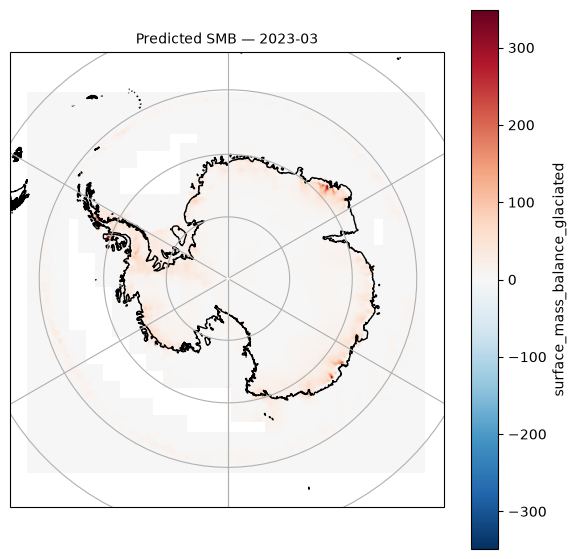

In [43]:
import cartopy.crs as ccrs
import xarray as xr
from matplotlib import pyplot as plt

time_idx = 2

actual_time = preds_ds.time[time_idx].values
actual_time_str = str(actual_time)[:7]

map_proj = ccrs.SouthPolarStereo(central_longitude=0.0)

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": map_proj})

preds_ds.isel(time=time_idx).surface_mass_balance_glaciated.plot(
            ax=ax, x="x", y="y", transform=ccrs.SouthPolarStereo(), add_colorbar=True, cmap="RdBu_r")

ax.coastlines("10m")
ax.gridlines(draw_labels=False)
ax.set_title(f"Predicted SMB — {actual_time_str}", fontsize=10)
plt.show()